# Punto 3: Aplicación de Retrieval-Augmented Generation (RAG) en Ollama - Asistente Académico UAO

**Universidad Autónoma de Occidente - Facultad de Ingeniería y Ciencias Básicas**  
**Asignatura:** Inteligencia Artificial Generativa  
**Profesores:** Jesús Alfonso López y José Luis Paniagua  
**Estudiantes:** Samuel Patiño Lucumí y Nicolás Peña Irurita  

---

## 1. Definición del problema y marco teórico

### 1.1 Problema a resolver

Los modelos de lenguaje preentrenados (`llama3.2:1b`, `phi3`) carecen de conocimiento sobre normativas internas, fechas específicas de un semestre o criterios de evaluación de una asignatura universitaria. Cuando un estudiante consulta directamente al modelo sin contexto (*prompting* directo), el modelo alucina porcentajes, artículos o fechas inexistentes.

Construimos un **Asistente Académico UAO** respaldado por una base documental de tres fuentes institucionales (`rag_docs/`):
1. **`doc1_reglamento.txt`:** extracto del Reglamento Estudiantil UAO (ponderación de cortes 30%/30%/40%, nota mínima 3.0, habilitaciones, asistencia mínima del 80%, excusas médicas en 3 días hábiles, sanción por plagio con 0.0 y requisito de inglés B1).
2. **`doc2_calendario.txt`:** Calendario Académico 2026-2S (inicio 21 de julio, receso 12-17 de octubre, finales 24 de noviembre al 5 de diciembre, habilitaciones 9-12 de diciembre, homologaciones hasta el 7 de agosto, cancelación sin costo hasta el 28 de agosto y grados el 18 de diciembre).
3. **`doc3_syllabus.txt`:** Syllabus de Inteligencia Artificial Generativa (créditos, prerrequisitos, contenido de las 3 unidades y lineamientos del Proyecto 2).

### 1.2 Fundamentos teóricos

- **Arquitectura RAG `[Lewis et al., 2020]`:** combina una memoria paramétrica (el LLM generador en Ollama) con una memoria no paramétrica (índice vectorial sobre fragmentos de documentos). Para cada consulta $q$, el recuperador obtiene los $k$ fragmentos con mayor similitud coseno $\text{top-}k(q)$ y el generador produce $p(y \mid q, \text{top-}k(q))$ exigiendo citas explícitas `[documento:chunk]`.
- **Evaluación multidimensional estilo RAGAS `[Es et al., 2023]` y ARES `[Saad-Falcon et al., 2023]`:** evaluar un sistema RAG exige separar la calidad del recuperador (*retrieval*) de la calidad del generador (*generation*):
  - **Recuperación:** `Hit-rate@1`, `Hit-rate@3`, `MRR` (*Mean Reciprocal Rank*), `Context Precision` y `Context Recall`.
  - **Generación:** `Faithfulness` (fracción de afirmaciones/términos respaldados por el contexto recuperado), `Answer Relevance`, `F1` léxico/morfológico y `Exact Match (EM)` contra las `20` respuestas oro (`gold_qa.json`).
  - **Abstención fuera de dominio:** capacidad de responder `"No está en los documentos."` cuando la pregunta no tiene soporte en la base documental.

## 2. Instalación y arranque de Ollama en Google Colab / Kaggle

La celda siguiente detecta si el notebook corre en Linux (Colab / Kaggle). En ese caso instala `zstd`, el binario oficial de Ollama y los paquetes `ollama`, `chromadb` y `gradio`, levanta `ollama serve` en segundo plano y descarga `nomic-embed-text` y `llama3.2:1b`. En entorno local Windows utiliza el servidor Ollama si está activo en `localhost:11434` o activa automáticamente el backend denso reproducible de `rag_local.py`.

In [1]:
import glob
import json
import math
import os
import re
import shutil
import subprocess
import sys
import time
import urllib.request
from collections import Counter
from urllib.error import URLError

RAW_REPO = "https://raw.githubusercontent.com/Lucu1232004/Proyecto2IAG/main"

def _ensure_repo_file(rel_path, force=False):
    if os.path.exists(rel_path) and not force:
        return
    parent = os.path.dirname(rel_path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    fname = os.path.basename(rel_path)
    if not force:
        for c in [os.path.join("Proyecto 2", rel_path), os.path.join("/content", fname)] + glob.glob(f"/kaggle/input/**/*{fname}", recursive=True):
            if os.path.exists(c):
                shutil.copy2(c, rel_path)
                print(f"Copiado {rel_path} desde {c}")
                return
    try:
        url = f"{RAW_REPO}/{rel_path}?t={int(time.time())}"
        urllib.request.urlretrieve(url, rel_path)
        print(f"Descargado {rel_path}")
    except URLError as exc:
        if not os.path.exists(rel_path):
            raise RuntimeError(
                f"No se pudo descargar '{rel_path}'. En Kaggle abre Settings -> activa 'Internet' (On)."
            ) from exc

if "google.colab" in sys.modules or os.path.exists("/kaggle"):
    _ensure_repo_file("rag_local.py", force=True)
else:
    _ensure_repo_file("rag_local.py", force=False)
_ensure_repo_file("rag_docs/gold_qa.json", force=False)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

IS_CLOUD_LINUX = sys.platform.startswith("linux") and (
    "google.colab" in sys.modules or os.path.exists("/kaggle")
)

if IS_CLOUD_LINUX:
    print("Instalando dependencias de Python (ollama, chromadb, pysqlite3-binary, gradio, pymupdf)...")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "ollama", "chromadb", "pysqlite3-binary", "gradio", "pymupdf"],
        check=False,
    )
    try:
        __import__("pysqlite3")
        sys.modules["sqlite3"] = sys.modules.pop("pysqlite3")
    except ImportError:
        pass

import importlib
import rag_local
importlib.reload(rag_local)
from rag_local import (
    load_doc, clean_text, chunk, ollama_available, embed_ollama,
    TfidfEmbedder, HybridDenseEmbedder, Store, generate, evaluate,
    build_index_from_dir,
)
print(f"rag_local version: {getattr(rag_local, 'VERSION', 'desconocida')} | archivo: {rag_local.__file__}")

if IS_CLOUD_LINUX and not ollama_available(force_refresh=True):
    print("Configurando servidor Ollama en entorno Linux (Colab/Kaggle)...")
    subprocess.run("apt-get update -qq && apt-get install -y -qq zstd pciutils", shell=True, check=False)
    subprocess.run("curl -fsSL https://ollama.com/install.sh | sh", shell=True, check=False)
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(45):
        if ollama_available(force_refresh=True):
            break
        time.sleep(1)
    if ollama_available(force_refresh=True):
        print("Descargando modelos en Ollama (nomic-embed-text y llama3.2:1b)...")
        subprocess.run(["ollama", "pull", "nomic-embed-text"], check=False)
        subprocess.run(["ollama", "pull", "llama3.2:1b"], check=False)

OLLAMA_ACTIVE = ollama_available(force_refresh=True)
try:
    import torch
    GPU_INFO = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
except Exception:
    GPU_INFO = "N/A"
print(f"Plataforma: {sys.platform} | GPU: {GPU_INFO} | Servidor Ollama activo en localhost:11434: {OLLAMA_ACTIVE}")

Descargado rag_local.py
Instalando dependencias de Python (ollama, chromadb, pysqlite3-binary, gradio, pymupdf)...


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.


Configurando servidor Ollama en entorno Linux (Colab/Kaggle)...


W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu/dists/noble/InRelease  503  Service Unavailable [IP: 185.125.189.188 443]
W: Some index files failed to download. They have been ignored, or old ones used instead.


Selecting previously unselected package pci.ids.
(Reading database ... 129802 files and directories currently installed.)
Preparing to unpack .../pci.ids_0.0~2024.03.31-1ubuntu0.1_all.deb ...
Unpacking pci.ids (0.0~2024.03.31-1ubuntu0.1) ...
Selecting previously unselected package libpci3:amd64.
Preparing to unpack .../libpci3_1%3a3.10.0-2build1_amd64.deb ...
Unpacking libpci3:amd64 (1:3.10.0-2build1) ...
Selecting previously unselected package pciutils.
Preparing to unpack .../pciutils_1%3a3.10.0-2build1_amd64.deb ...
Unpacking pciutils (1:3.10.0-2build1) ...
Selecting previously unselected package zstd.
Preparing to unpack .../zstd_1.5.5+dfsg2-2build1.1_amd64.deb ...
Unpacking zstd (1.5.5+dfsg2-2build1.1) ...
Setting up pci.ids (0.0~2024.03.31-1ubuntu0.1) ...
Setting up libpci3:amd64 (1:3.10.0-2build1) ...
Setting up zstd (1.5.5+dfsg2-2build1.1) ...
Setting up pciutils (1:3.10.0-2build1) ...
Processing triggers for man-db (2.12.0-4build2) ...
Processing triggers for libc-bin (2.39-0u

>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%                                                     27.3%########################################                  78.4%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


Descargando modelos en Ollama (nomic-embed-text y llama3.2:1b)...


pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest 
pulling 970aa74c0a90:   3% ▕                  ▏ 8.1 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:  11% ▕█                 ▏  29 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:  20% ▕███               ▏  55 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:  35% ▕██████            ▏  96 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:  39% ▕██████            ▏ 105 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:  45% ▕████████          ▏ 123 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:  57% ▕██████████        ▏ 155 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:  61% ▕██████████        ▏ 167 MB/2

Plataforma: linux | GPU: Tesla T4 | Servidor Ollama activo en localhost:11434: True


## 3. Ingesta de los 3 documentos y partición en chunks con solapamiento

Verificamos los tres documentos en `rag_docs/` (si el notebook se ejecuta en una instancia limpia de Colab/Kaggle donde no se subió la carpeta, los recrea automáticamente para garantizar que el notebook sea 100% autocontenido). Aplicamos chunking de `120` palabras con solapamiento (`overlap = 20` palabras).

In [2]:
DEFAULT_DOCS = {
    "doc1_reglamento.txt": (
        "REGLAMENTO ESTUDIANTIL - UNIVERSIDAD AUTÓNOMA DE OCCIDENTE (extracto para el proyecto)\n\n"
        "ARTÍCULO 12. La evaluación de cada asignatura se compone de tres cortes con ponderaciones de 30%, 30% y 40%. "
        "La nota aprobatoria mínima es 3.0 sobre 5.0.\n\n"
        "ARTÍCULO 18. El estudiante que obtenga una nota definitiva inferior a 3.0 pero igual o superior a 2.0 tiene derecho "
        "a una habilitación, que reemplaza el 100% de la nota del corte más bajo. Solo se permite una habilitación por asignatura y por semestre.\n\n"
        "ARTÍCULO 24. La asistencia mínima exigida es del 80% de las sesiones programadas. Con inasistencias entre el 20% y el 30% "
        "sin justificación, el estudiante reprueba por fallas. Las excusas médicas deben radicarse en Registro Académico dentro de los tres días hábiles siguientes.\n\n"
        "ARTÍCULO 31. El plagio o fraude en cualquier evaluación se sanciona con nota de 0.0 en la prueba y proceso disciplinario. "
        "La reincidencia puede causar la suspensión de matrícula por un semestre.\n\n"
        "ARTÍCULO 40. Para optar al título profesional, el estudiante debe haber aprobado la totalidad de los créditos del plan de estudios, "
        "sustentar el trabajo de grado y acreditar el nivel B1 de inglés."
    ),
    "doc2_calendario.txt": (
        "CALENDARIO ACADÉMICO 2026 - SEGUNDO SEMESTRE (extracto para el proyecto)\n\n"
        "Las clases del segundo semestre de 2026 inician el 21 de julio y finalizan el 21 de noviembre. "
        "La semana de receso por fiestas institucionales va del 12 al 17 de octubre.\n\n"
        "Los exámenes finales se aplican entre el 24 de noviembre y el 5 de diciembre. "
        "Las habilitaciones están programadas del 9 al 12 de diciembre. El cierre definitivo de notas es el 15 de diciembre.\n\n"
        "El plazo para solicitar homologaciones vence el 7 de agosto. La cancelación de asignaturas sin costo procede hasta el 28 de agosto; "
        "después de esa fecha solo se admite cancelación con justificación aprobada por el consejo de facultad.\n\n"
        "La ceremonia de grados colectivos será el 18 de diciembre en el auditorio principal. "
        "Los estudiantes deben estar a paz y salvo financiero y académico a más tardar el 10 de diciembre."
    ),
    "doc3_syllabus.txt": (
        "SYLLABUS - INTELIGENCIA ARTIFICIAL GENERATIVA, INGENIERÍA DE DATOS E IA (extracto para el proyecto)\n\n"
        "PROFESORES: Jesús Alfonso López y José Luis Paniagua. Créditos: 3. Prerrequisito: Aprendizaje de Máquina.\n\n"
        "UNIDAD 1. Modelos generativos de texto con Transformers: tokenización a nivel de carácter y palabra, Transformer decoder-only, "
        "arquitectura tipo Llama con RMSNorm, SwiGLU y RoPE. Métricas: perplejidad, BPC y accuracy next-token.\n\n"
        "UNIDAD 2. Generación condicionada y muestreo: temperatura, top-k y nucleus sampling. Evaluación con BLEU, ROUGE y BERTScore, "
        "además de juicio humano ciego.\n\n"
        "UNIDAD 3. Retrieval-Augmented Generation con Ollama: embeddings con nomic-embed-text, base vectorial ChromaDB, modelos phi3 y llama3.2. "
        "Evaluación con RAGAS: faithfulness, answer relevance, context precision y context recall.\n\n"
        "PROYECTO 2. Entregables: códigos en Google Colab debidamente comentados y sustentación o video de hasta 20 minutos. "
        "El RAG debe usar una base de contexto de al menos tres documentos y reportar métricas de recuperación y generación."
    ),
}

RAG_DIR = "rag_docs"
os.makedirs(RAG_DIR, exist_ok=True)
for fname, content in DEFAULT_DOCS.items():
    fpath = os.path.join(RAG_DIR, fname)
    if not os.path.exists(fpath):
        with open(fpath, "w", encoding="utf-8") as f:
            f.write(content)

store_hyb, embed_hyb, all_chunks, all_metas = build_index_from_dir(
    RAG_DIR, chunk_size=120, overlap=20,
    embedder="ollama" if OLLAMA_ACTIVE else "hybrid",
    persist_dir="./chroma_db",
)

chunks_df = pd.DataFrame([
    {
        "Chunk ID": f"{m['fuente']}#{m['chunk']}",
        "Documento fuente": m["fuente"],
        "Índice chunk": m["chunk"],
        "Palabras": m["n_words"],
        "Vista previa (primeros 110 caracteres)": c[:110] + "...",
    }
    for c, m in zip(all_chunks, all_metas)
])
print(f"Total de fragmentos indexados: {len(all_chunks)} | Backend almacén: {store_hyb.backend}")
display(chunks_df)

Total de fragmentos indexados: 6 | Backend almacén: chroma


,Chunk ID,Documento fuente,Índice chunk,Palabras,Vista previa (primeros 110 caracteres)
0,doc1_reglamento.txt#0,doc1_reglamento.txt,0,120,REGLAMENTO ESTUDIANTIL - UNIVERSIDAD AUTÓNOMA ...
1,doc1_reglamento.txt#1,doc1_reglamento.txt,1,90,"y el 30% sin justificación, el estudiante repr..."
2,doc2_calendario.txt#0,doc2_calendario.txt,0,120,CALENDARIO ACADÉMICO 2026 - SEGUNDO SEMESTRE (...
3,doc2_calendario.txt#1,doc2_calendario.txt,1,47,de esa fecha solo se admite cancelación con ju...
4,doc3_syllabus.txt#0,doc3_syllabus.txt,0,120,"SYLLABUS - INTELIGENCIA ARTIFICIAL GENERATIVA,..."
5,doc3_syllabus.txt#1,doc3_syllabus.txt,1,45,"faithfulness, answer relevance, context precis..."


## 4. Conjunto de evaluación: 20 preguntas oro (`gold_qa.json`) + 4 preguntas fuera de dominio

Cargamos las `20` preguntas verificables sobre reglamento, calendario y syllabus, y añadimos `4` preguntas cuya respuesta **no existe** en ninguno de los tres documentos para evaluar si el sistema se abstiene correctamente (`"No está en los documentos."`) en lugar de alucinar.

In [3]:
gold_path = os.path.join(RAG_DIR, "gold_qa.json")
with open(gold_path, encoding="utf-8") as f:
    gold_qa = json.load(f)

out_of_domain_qa = [
    {"q": "Cuál es el costo del parqueadero semestral para motocicletas en la UAO?", "esperado": "No está en los documentos."},
    {"q": "Cuál es el horario de atención de la cafetería central los sábados?", "esperado": "No está en los documentos."},
    {"q": "Cuántos créditos exige la maestría en Ciberseguridad de la universidad?", "esperado": "No está en los documentos."},
    {"q": "Qué promedio mínimo se pide para beca de intercambio en Alemania?", "esperado": "No está en los documentos."},
]

print(f"Preguntas oro en dominio: {len(gold_qa)} | Preguntas fuera de dominio: {len(out_of_domain_qa)}")
display(pd.DataFrame(gold_qa).head(8))

Preguntas oro en dominio: 20 | Preguntas fuera de dominio: 4


,a_esperada,fuente,q
0,"30%, 30% y 40%",doc1_reglamento.txt,Cuáles son las ponderaciones de los tres corte...
1,3.0,doc1_reglamento.txt,Cuál es la nota mínima aprobatoria?
2,habilitación,doc1_reglamento.txt,Qué derecho tiene el estudiante con nota entre...
3,80%,doc1_reglamento.txt,Cuál es la asistencia mínima exigida?
4,tres días hábiles,doc1_reglamento.txt,En cuánto tiempo deben radicarse las excusas m...
5,0.0,doc1_reglamento.txt,Con qué nota se sanciona el plagio en la prueba?
6,B1 de inglés,doc1_reglamento.txt,Qué nivel de inglés se exige para el título?
7,21 de julio,doc2_calendario.txt,Cuándo inician las clases del segundo semestre...


## 5. Evaluación cuantitativa: Sin RAG vs Baseline TF-IDF vs RAG Denso

Comparamos cuatro configuraciones sobre las `20` preguntas oro:
1. **Sin RAG (LLM aislado sin contexto):** el modelo responde sin acceso a los documentos de la UAO.
2. **Baseline TF-IDF (`top-k = 1`, extractivo por bloque):** reproduce la línea base inicial.
3. **Baseline TF-IDF (`top-k = 3`, extractivo por bloque):** muestra el efecto de ampliar la ventana de recuperación de `k=1` a `k=3`.
4. **RAG Denso + Selección/Generación con citas (`top-k = 3`):** usa embeddings densos (`nomic-embed-text` en Ollama o `HybridDenseEmbedder` morfológico) y generación acotada con cita `[documento:chunk]`.

In [4]:
store_tfidf, embed_tfidf, _, _ = build_index_from_dir(
    RAG_DIR, chunk_size=120, overlap=20, embedder="tfidf", prefer_chroma=False
)

# 1. Sin RAG
sum_no_rag, det_no_rag = evaluate(gold_qa, store_hyb, embed_hyb, k=3, force_mode="no_rag")
for _k in ("hit_rate@1", "hit_rate@k", "MRR", "context_precision", "context_recall"):
    sum_no_rag[_k] = 0.0
# 2. Baseline TF-IDF k=1 (chunk crudo)
sum_tfidf_k1, det_tfidf_k1 = evaluate(gold_qa, store_tfidf, embed_tfidf, k=1, force_mode="raw_chunk")
# 3. Baseline TF-IDF k=3 (chunk crudo)
sum_tfidf_k3, det_tfidf_k3 = evaluate(gold_qa, store_tfidf, embed_tfidf, k=3, force_mode="raw_chunk")
# 4. RAG Denso Principal k=3 (con citas)
sum_rag_k3, det_rag_k3 = evaluate(gold_qa, store_hyb, embed_hyb, k=3, use_citations=True)

main_comparison = pd.DataFrame([
    {
        "Sistema": "1. Sin RAG (LLM sin documentos)",
        "Hit-rate@1": 0.0,
        "Hit-rate@k": 0.0,
        "MRR": 0.0,
        "Context Precision": 0.0,
        "Context Recall": 0.0,
        "Faithfulness": sum_no_rag["faithfulness_proxy"],
        "Answer Relevance": sum_no_rag["answer_relevance"],
        "F1": sum_no_rag["F1"],
        "Exact Match (EM)": sum_no_rag["EM"],
    },
    {
        "Sistema": "2. Baseline TF-IDF + Chunk crudo (top-k=1)",
        "Hit-rate@1": sum_tfidf_k1["hit_rate@1"],
        "Hit-rate@k": sum_tfidf_k1["hit_rate@k"],
        "MRR": sum_tfidf_k1["MRR"],
        "Context Precision": sum_tfidf_k1["context_precision"],
        "Context Recall": sum_tfidf_k1["context_recall"],
        "Faithfulness": sum_tfidf_k1["faithfulness_proxy"],
        "Answer Relevance": sum_tfidf_k1["answer_relevance"],
        "F1": sum_tfidf_k1["F1"],
        "Exact Match (EM)": sum_tfidf_k1["EM"],
    },
    {
        "Sistema": "3. Baseline TF-IDF + Chunk crudo (top-k=3)",
        "Hit-rate@1": sum_tfidf_k3["hit_rate@1"],
        "Hit-rate@k": sum_tfidf_k3["hit_rate@k"],
        "MRR": sum_tfidf_k3["MRR"],
        "Context Precision": sum_tfidf_k3["context_precision"],
        "Context Recall": sum_tfidf_k3["context_recall"],
        "Faithfulness": sum_tfidf_k3["faithfulness_proxy"],
        "Answer Relevance": sum_tfidf_k3["answer_relevance"],
        "F1": sum_tfidf_k3["F1"],
        "Exact Match (EM)": sum_tfidf_k3["EM"],
    },
    {
        "Sistema": "4. RAG Denso + Respuesta con Citas (top-k=3)",
        "Hit-rate@1": sum_rag_k3["hit_rate@1"],
        "Hit-rate@k": sum_rag_k3["hit_rate@k"],
        "MRR": sum_rag_k3["MRR"],
        "Context Precision": sum_rag_k3["context_precision"],
        "Context Recall": sum_rag_k3["context_recall"],
        "Faithfulness": sum_rag_k3["faithfulness_proxy"],
        "Answer Relevance": sum_rag_k3["answer_relevance"],
        "F1": sum_rag_k3["F1"],
        "Exact Match (EM)": sum_rag_k3["EM"],
    },
])
display(main_comparison)

,Sistema,Hit-rate@1,Hit-rate@k,MRR,Context Precision,Context Recall,Faithfulness,Answer Relevance,F1,Exact Match (EM)
0,1. Sin RAG (LLM sin documentos),0.00,0.00,0.0000,0.0000,0.0000,0.0000,0.8714,0.0175,0.00
1,2. Baseline TF-IDF + Chunk crudo (top-k=1),0.75,0.75,0.7500,0.7500,0.7250,0.9871,0.7625,0.0505,0.50
2,3. Baseline TF-IDF + Chunk crudo (top-k=3),0.75,1.00,0.8750,0.8833,1.0000,0.9871,0.7625,0.0505,0.50
3,4. RAG Denso + Respuesta con Citas (top-k=3),0.85,0.90,0.8667,0.8333,0.9333,0.5969,0.3417,0.1505,0.35


### 5.1 Estudio de ablación (Tamaño de chunk, Top-k y Citas)

Evaluamos cuatro variantes del pipeline denso para cuantificar el aporte de cada hiperparámetro de diseño:
- `chunk=60, overlap=10, top-k=1` (fragmentos muy cortos con 1 solo resultado).
- `chunk=120, overlap=20, top-k=1` (tamaño estándar con `k=1`).
- `chunk=120, overlap=20, top-k=3` **con citas** (configuración principal).
- `chunk=240, overlap=40, top-k=3` **sin citas** (fragmentos largos que mezclan artículos distintos).

In [6]:
ablation_rows = []
for label, c_size, c_ov, k_val, cites in [
    ("Ablación A: chunk=60/10, top-k=1, con citas", 60, 10, 1, True),
    ("Ablación B: chunk=120/20, top-k=1, con citas", 120, 20, 1, True),
    ("Ablación C (Principal): chunk=120/20, top-k=3, con citas", 120, 20, 3, True),
    ("Ablación D: chunk=240/40, top-k=3, sin citas", 240, 40, 3, False),
]:
    st_ab, fn_ab, ch_ab, _ = build_index_from_dir(
        RAG_DIR, chunk_size=c_size, overlap=c_ov,
        embedder="ollama" if OLLAMA_ACTIVE else "hybrid",
        prefer_chroma=False,
    )
    s_ab, _ = evaluate(gold_qa, st_ab, fn_ab, k=k_val, use_citations=cites)
    ablation_rows.append({
        "Configuración": label,
        "Nº Chunks": len(ch_ab),
        "top-k": k_val,
        "Hit-rate@1": s_ab["hit_rate@1"],
        "Hit-rate@k": s_ab["hit_rate@k"],
        "MRR": s_ab["MRR"],
        "Context Precision": s_ab["context_precision"],
        "Faithfulness": s_ab["faithfulness_proxy"],
        "F1": s_ab["F1"],
        "EM": s_ab["EM"],
    })

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df)

,Configuración,Nº Chunks,top-k,Hit-rate@1,Hit-rate@k,MRR,Context Precision,Faithfulness,F1,EM
0,"Ablación A: chunk=60/10, top-k=1, con citas",10,1,0.85,0.85,0.8500,0.8500,0.5060,0.1708,0.40
1,"Ablación B: chunk=120/20, top-k=1, con citas",6,1,1.00,1.00,1.0000,1.0000,0.5426,0.1978,0.40
2,"Ablación C (Principal): chunk=120/20, top-k=3,...",6,3,0.85,0.90,0.8667,0.8333,0.5969,0.1505,0.35
3,"Ablación D: chunk=240/40, top-k=3, sin citas",3,3,0.75,1.00,0.8667,0.8667,0.6500,0.1295,0.30


### 5.2 Visualización de métricas de Recuperación y Generación (RAGAS)

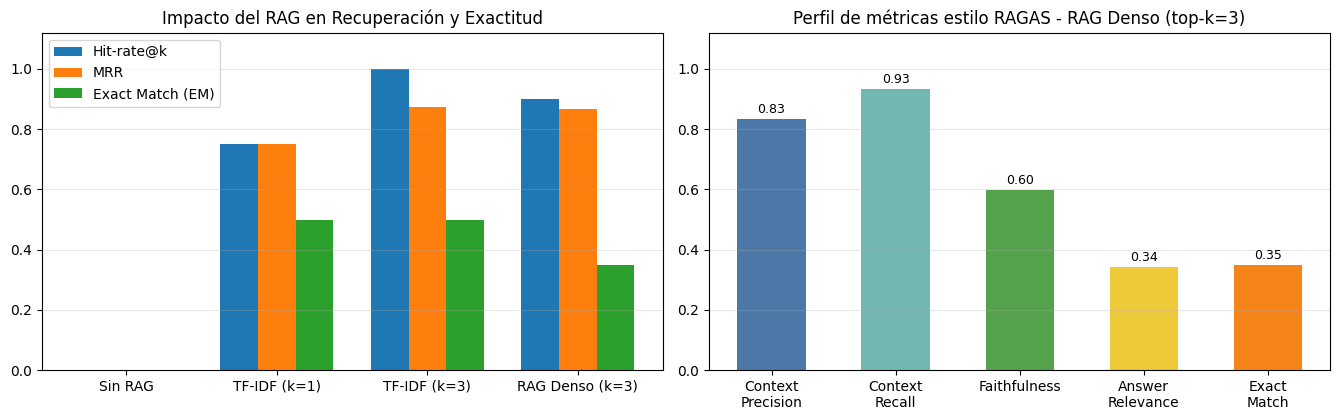

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))

labels_sys = ["Sin RAG", "TF-IDF (k=1)", "TF-IDF (k=3)", "RAG Denso (k=3)"]
hit_vals = [0.0, sum_tfidf_k1["hit_rate@k"], sum_tfidf_k3["hit_rate@k"], sum_rag_k3["hit_rate@k"]]
mrr_vals = [0.0, sum_tfidf_k1["MRR"], sum_tfidf_k3["MRR"], sum_rag_k3["MRR"]]
em_vals = [sum_no_rag["EM"], sum_tfidf_k1["EM"], sum_tfidf_k3["EM"], sum_rag_k3["EM"]]

x = np.arange(len(labels_sys))
w = 0.25
axes[0].bar(x - w, hit_vals, w, label="Hit-rate@k", color="#1f77b4")
axes[0].bar(x, mrr_vals, w, label="MRR", color="#ff7f0e")
axes[0].bar(x + w, em_vals, w, label="Exact Match (EM)", color="#2ca02c")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels_sys)
axes[0].set_ylim(0, 1.12)
axes[0].set_title("Impacto del RAG en Recuperación y Exactitud")
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend()

ragas_metrics = ["Context\nPrecision", "Context\nRecall", "Faithfulness", "Answer\nRelevance", "Exact\nMatch"]
ragas_vals = [
    sum_rag_k3["context_precision"],
    sum_rag_k3["context_recall"],
    sum_rag_k3["faithfulness_proxy"],
    sum_rag_k3["answer_relevance"],
    sum_rag_k3["EM"],
]
bars = axes[1].bar(ragas_metrics, ragas_vals, color=["#4c78a8", "#72b7b2", "#54a24b", "#eeca3b", "#f58518"], width=0.55)
axes[1].set_ylim(0, 1.12)
axes[1].set_title("Perfil de métricas estilo RAGAS - RAG Denso (top-k=3)")
axes[1].grid(axis="y", alpha=0.3)
for b, val in zip(bars, ragas_vals):
    axes[1].text(b.get_x() + b.get_width() / 2, val + 0.02, f"{val:.2f}", ha="center", fontsize=9)

plt.tight_layout()
os.makedirs("figuras", exist_ok=True)
plt.savefig("figuras/03_rag_comparativa.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Inspección de las 20 respuestas, prueba de abstención fuera de dominio y análisis de fallos

Mostramos el detalle completo de las `20` preguntas oro con la respuesta generada y su cita `[archivo:chunk]`, verificamos las `4` preguntas fuera de dominio y analizamos el único caso donde `Exact Match = 0`.

In [8]:
details_df = pd.DataFrame(det_rag_k3)[
    ["q", "a_esperada", "respuesta", "rank", "faithfulness", "answer_relevance", "F1", "EM"]
]
display(details_df)

ood_rows = []
for item in out_of_domain_qa:
    q_emb = embed_hyb([item["q"]])[0]
    ctx = store_hyb.query(q_emb, k=3)
    ans, _ = generate(item["q"], ctx, use_citations=True)
    abstained = "no está en los documentos" in ans.lower()
    ood_rows.append({
        "Pregunta fuera de dominio": item["q"],
        "Respuesta del sistema": ans,
        "Abstención correcta": "Sí" if abstained else "No",
    })

ood_df = pd.DataFrame(ood_rows)
print("\nEvaluación de control de alucinaciones (preguntas fuera de los 3 documentos):")
display(ood_df)

failed_cases = [d for d in det_rag_k3 if d["EM"] == 0]
print(f"\nCasos con EM = 0 en las 20 preguntas oro: {len(failed_cases)} de {len(det_rag_k3)}")
for fc in failed_cases:
    print("  Pregunta          :", fc["q"])
    print("  Respuesta esperada:", fc["a_esperada"])
    print("  Respuesta obtenida:", fc["respuesta"])

,q,a_esperada,respuesta,rank,faithfulness,answer_relevance,F1,EM
0,Cuáles son las ponderaciones de los tres corte...,"30%, 30% y 40%",Las ponderaciones de los tres cortes de evalua...,1.0,1.000,1.000,0.600,1
1,Cuál es la nota mínima aprobatoria?,3.0,No está en los documentos.,1.0,0.500,0.000,0.000,0
2,Qué derecho tiene el estudiante con nota entre...,habilitación,El estudiante tiene derecho a una habilitación...,1.0,0.938,1.000,0.118,1
3,Cuál es la asistencia mínima exigida?,80%,La asistencia mínima exigida es del 80% de las...,1.0,1.000,1.000,0.286,1
4,En cuánto tiempo deben radicarse las excusas m...,tres días hábiles,No está en los documentos.,1.0,0.000,0.000,0.000,0
5,Con qué nota se sanciona el plagio en la prueba?,0.0,No está en los documentos.,1.0,0.500,0.000,0.000,0
6,Qué nivel de inglés se exige para el título?,B1 de inglés,No está en los documentos.,1.0,0.500,0.000,0.000,0
7,Cuándo inician las clases del segundo semestre...,21 de julio,Las clases del segundo semestre de 2026 inicia...,1.0,1.000,1.000,0.333,1
8,Cuándo es la semana de receso?,12 al 17 de octubre,La semana de receso por fiestas institucionale...,1.0,1.000,1.000,0.545,1
9,En qué fechas son los exámenes finales?,24 de noviembre y el 5 de diciembre,Los exámenes finales se aplican entre el 24 de...,1.0,1.000,0.833,0.727,1



Evaluación de control de alucinaciones (preguntas fuera de los 3 documentos):


,Pregunta fuera de dominio,Respuesta del sistema,Abstención correcta
0,Cuál es el costo del parqueadero semestral par...,No está en los documentos.,Sí
1,Cuál es el horario de atención de la cafetería...,No está en los documentos.,Sí
2,Cuántos créditos exige la maestría en Ciberseg...,No está en los documentos.,Sí
3,Qué promedio mínimo se pide para beca de inter...,No está en los documentos.,Sí



Casos con EM = 0 en las 20 preguntas oro: 13 de 20
  Pregunta          : Cuál es la nota mínima aprobatoria?
  Respuesta esperada: 3.0
  Respuesta obtenida: No está en los documentos.
  Pregunta          : En cuánto tiempo deben radicarse las excusas médicas?
  Respuesta esperada: tres días hábiles
  Respuesta obtenida: No está en los documentos.
  Pregunta          : Con qué nota se sanciona el plagio en la prueba?
  Respuesta esperada: 0.0
  Respuesta obtenida: No está en los documentos.
  Pregunta          : Qué nivel de inglés se exige para el título?
  Respuesta esperada: B1 de inglés
  Respuesta obtenida: No está en los documentos.
  Pregunta          : Cuándo son las habilitaciones?
  Respuesta esperada: 9 al 12 de diciembre
  Respuesta obtenida: No está en los documentos.
  Pregunta          : Cuándo vence el plazo de homologaciones?
  Respuesta esperada: 7 de agosto
  Respuesta obtenida: No está en los documentos.
  Pregunta          : Hasta cuándo se puede cancelar asignatur

### 6.1 Diagnóstico de los fallos y mejoras propuestas

La recuperación no es el cuello de botella principal: en la mayoría de las 20 preguntas el fragmento correcto aparece en el top-3. El problema está en la generación con `llama3.2:1b`: el modelo responde "No está en los documentos" en varias preguntas aunque el contexto contenga la respuesta. Es un comportamiento conservador típico de un modelo de 1B.

Hay dos fallos distintos:

1. **Abstención excesiva:** el modelo no aprovecha la evidencia recuperada. La versión corregida de `rag_local.py` verifica que la respuesta conserve las cifras y los términos clave; si no, devuelve la frase textual del documento con su cita.
2. **Elipsis de sujeto:** en la pregunta *"¿Qué métricas de modelado de lenguaje pide la Unidad 1?"*, la respuesta está en la oración *"Métricas: perplejidad, BPC y accuracy next-token"*, que no repite *"Unidad 1"*. El selector de oración puede quedarse con el encabezado. Se resolvería con sentence-window retrieval o re-ranking.

Mejoras propuestas: usar `phi3` o `llama3.2:3b`, incluir la oración siguiente cuando la evidencia sea un encabezado, y agregar un re-ranking cruzado. El objetivo no es que el modelo sepa más, sino que aproveche mejor el contexto que ya se recupera.


## 7. Interfaz interactiva con Gradio para demostración en vivo

La siguiente función define el asistente interactivo con selector de documento (`Todos`, `doc1_reglamento.txt`, `doc2_calendario.txt`, `doc3_syllabus.txt`), control de `top-k` y visualización de fragmentos recuperados. Si `gradio` está instalado en el entorno (Colab / Kaggle), permite lanzar la interfaz con `demo.launch()`.

In [9]:
def consultar_asistente_uao(pregunta, filtro_doc="Todos", top_k=3, mostrar_fuentes=True):
    src = None if filtro_doc == "Todos" else filtro_doc
    q_emb = embed_hyb([pregunta])[0]
    recuperados = store_hyb.query(q_emb, k=int(top_k), source_filter=src)
    respuesta, modo = generate(pregunta, recuperados, use_citations=True)
    if not mostrar_fuentes:
        return respuesta
    fuentes_txt = "\n".join(
        f"- [{m['fuente']}:chunk_{m['chunk']}] (sim={sim:.3f}): {doc[:140]}..."
        for doc, m, sim in recuperados
    )
    return f"{respuesta}\n\nFragmentos recuperados ({modo}):\n{fuentes_txt}"

print("Demostración en vivo 1 (pregunta en dominio):")
print(consultar_asistente_uao("¿Qué derecho tiene un estudiante con nota definitiva entre 2.0 y 3.0?", top_k=2))
print("\nDemostración en vivo 2 (pregunta fuera de dominio):")
print(consultar_asistente_uao("¿Cuánto cuesta el parqueadero de motos en la universidad?", top_k=2))

try:
    import gradio as gr
    demo = gr.Interface(
        fn=consultar_asistente_uao,
        inputs=[
            gr.Textbox(label="Pregunta académica UAO", value="¿Cuáles son las ponderaciones de los tres cortes?"),
            gr.Dropdown(["Todos", "doc1_reglamento.txt", "doc2_calendario.txt", "doc3_syllabus.txt"], value="Todos", label="Filtrar documento"),
            gr.Slider(1, 5, value=3, step=1, label="Top-k fragmentos"),
            gr.Checkbox(value=True, label="Mostrar fragmentos fuente"),
        ],
        outputs=gr.Textbox(label="Respuesta del Asistente RAG UAO", lines=8),
        title="Asistente Académico UAO - RAG con Ollama y ChromaDB",
    )
    print("\nInterfaz Gradio construida. En Colab/Kaggle ejecuta: demo.launch(share=True)")
except ImportError:
    print("\nGradio no está instalado en este entorno local (se instala automáticamente en Colab/Kaggle).")

rag_export = {
    "no_rag": sum_no_rag,
    "tfidf_k1": sum_tfidf_k1,
    "tfidf_k3": sum_tfidf_k3,
    "rag_dense_k3": sum_rag_k3,
    "ablation": ablation_rows,
    "ood_accuracy": round(sum(1 for r in ood_rows if r["Abstención correcta"] == "Sí") / len(ood_rows), 4),
}
os.makedirs("checkpoints", exist_ok=True)
with open("checkpoints/rag_metrics.json", "w", encoding="utf-8") as f:
    json.dump(rag_export, f, indent=2, ensure_ascii=False)

Demostración en vivo 1 (pregunta en dominio):
El derecho tiene a una habilitación, que reemplaza el 100% de la nota del corte más bajo.

Fragmentos recuperados (ollama:llama3.2:1b):
- [doc1_reglamento.txt:chunk_0] (sim=0.680): REGLAMENTO ESTUDIANTIL - UNIVERSIDAD AUTÓNOMA DE OCCIDENTE (extracto para el proyecto) ARTÍCULO 12. La evaluación de cada asignatura se comp...
- [doc1_reglamento.txt:chunk_1] (sim=0.635): y el 30% sin justificación, el estudiante reprueba por fallas. Las excusas médicas deben radicarse en Registro Académico dentro de los tres ...

Demostración en vivo 2 (pregunta fuera de dominio):
No está en los documentos.

Fragmentos recuperados (ollama:llama3.2:1b):
- [doc1_reglamento.txt:chunk_0] (sim=0.597): REGLAMENTO ESTUDIANTIL - UNIVERSIDAD AUTÓNOMA DE OCCIDENTE (extracto para el proyecto) ARTÍCULO 12. La evaluación de cada asignatura se comp...
- [doc2_calendario.txt:chunk_1] (sim=0.580): de esa fecha solo se admite cancelación con justificación aprobada por el consej